# GPU Assignment II — HW4.a + HW4.5 (ONE GPU)

**RTX 4090 / 24 GB.** Professor Savitha V clarified that one GPU is sufficient and Part C is optional. This notebook runs the single-GPU experiments. Use the **same original Twitter CSV, SLICE, SEED, and split** throughout. Full-run requirements not implemented in this starter are marked as such. Run from repository root.


In [4]:
from pathlib import Path
import os
import subprocess
import torch

# Find the project relative to the notebook's working directory
cwd = Path.cwd().resolve()

candidates = [
    cwd,
    cwd / "gpu-assignment-ii",
    cwd.parent,
    cwd.parent / "gpu-assignment-ii",
]

ROOT = next(
    (p for p in candidates if (p / "configs" / "experiment.yaml").is_file()),
    None
)

assert ROOT is not None, f"Project not found. Current directory: {cwd}"

os.chdir(ROOT)

print("Project root:", ROOT)

subprocess.run(["nvidia-smi", "-L"], check=True)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

assert torch.cuda.is_available(), "CUDA GPU required"

print("GPU:", torch.cuda.get_device_name(0))
print(
    "GPU memory:",
    round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
    "GB"
)

Project root: /root/workspace/DATA266---2738/GPU_Assignment2/gpu-assignment-ii
GPU 0: NVIDIA GeForce RTX 4090 (UUID: GPU-49f6e7a5-0d30-4554-8244-7a00552b9b36)
PyTorch: 2.8.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 4090
GPU memory: 23.52 GB


## 1 — Dataset and reproducibility
Provide `data/twitter.csv`, set `slice` and `seed` in YAML. Exact row range is written to `results/row_range.json`. 70/15/15 stratified split.

In [9]:
%pip install -U pandas numpy pyyaml scikit-learn transformers datasets accelerate matplotlib seaborn tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 18.3 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 26.8 MB/s  0:00:00m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 32.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.0/13.0 MB 36.5 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 855.2/855.2 kB 26.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 36.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 37.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 23.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 40.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 37.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 43.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 37.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [19]:
%pip install -q datasets huggingface_hub

Note: you may need to restart the kernel to use updated packages.


In [27]:
from pathlib import Path
from datasets import load_dataset
import pandas as pd

data_dir = ROOT / "data"
data_dir.mkdir(parents=True, exist_ok=True)

# Download Twitter sentiment dataset
ds = load_dataset("cardiffnlp/tweet_eval", "sentiment")

# Combine predefined splits into one source dataset
df = pd.concat(
    [ds[s].to_pandas() for s in ["train", "validation", "test"]],
    ignore_index=True
)

df = df[["text", "label"]].dropna()

# Reproducible source ordering
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

output = data_dir / "twitter.csv"
df.to_csv(output, index=False)

print("Saved:", output)
print("Total rows:", len(df))
print("Classes:", df["label"].value_counts().to_dict())

README.md:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

sentiment/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.78MB            

sentiment/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  901kB            

sentiment/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

sentiment/validation-00000-of-00001.parq(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45615 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/12284 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Saved: /root/workspace/DATA266---2738/GPU_Assignment2/gpu-assignment-ii/data/twitter.csv
Total rows: 59899
Classes: {1: 27479, 2: 21043, 0: 11377}


In [28]:
from common import config, load_data

c = config()

start = int(c["slice"])
subset = df.iloc[start:start + 5000]

print("SEED:", c["seed"])
print("SLICE:", start)
print("Selected rows:", len(subset))
print("Class distribution:", subset["label"].value_counts().to_dict())

assert len(subset) > 0, "SLICE is outside the dataset"

tr, va, te, label_map = load_data(c)

print("\nTraining:", len(tr))
print("Validation:", len(va))
print("Testing:", len(te))
print("Classes:", label_map)

SEED: 42
SLICE: 0
Selected rows: 5000
Class distribution: {1: 2306, 2: 1790, 0: 904}

Training: 3500
Validation: 750
Testing: 750
Classes: {'0': 0, '1': 1, '2': 2}


In [29]:
import sys
from pathlib import Path
import yaml

# Project root from Cell 1
sys.path.insert(0, str(ROOT / "src"))

from common import config, load_data

# Read configuration
config_path = ROOT / "configs" / "experiment.yaml"
settings = yaml.safe_load(config_path.read_text())

# Validate SEED and SLICE
if settings.get("seed") is None or settings.get("slice") is None:
    raise ValueError(
        "Set seed and slice in configs/experiment.yaml first. "
        "Use your instructor-assigned HW4.a values."
    )

# Load configuration
c = config()

print("SEED:", c["seed"])
print("SLICE:", c["slice"])

# Load Twitter dataset
tr, va, te, label_map = load_data(c)

print("\nDataset loaded successfully!")
print("Training rows:", len(tr))
print("Validation rows:", len(va))
print("Testing rows:", len(te))
print("Total rows:", len(tr) + len(va) + len(te))
print("Classes:", label_map)

# Display selected row range
row_file = ROOT / "results" / "row_range.json"

if row_file.exists():
    print("\nSelected dataset rows:")
    print(row_file.read_text())
else:
    print("\nrow_range.json not generated yet")

SEED: 42
SLICE: 0

Dataset loaded successfully!
Training rows: 3500
Validation rows: 750
Testing rows: 750
Total rows: 5000
Classes: {'0': 0, '1': 1, '2': 2}

Selected dataset rows:
{
  "start_zero_based_inclusive": 0,
  "end_zero_based_inclusive": 4999,
  "rows_before_dropna": 5000,
  "rows_after_dropna": 5000,
  "label_map": {
    "0": 0,
    "1": 1,
    "2": 2
  }
}


## 2 — HW4.a BERT fine-tuning
Train baseline and capture epoch-by-epoch loss, validation accuracy, peak GPU allocation, wall time, and best validation epoch.

In [30]:
subprocess.run([sys.executable,'src/train_bert.py'],check=True)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4933.95it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

{'epoch': 1, 'train_loss': 0.8408934147390601, 'val_loss': 0.742498073172062, 'val_accuracy': 0.6466666666666666}


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.30it/s]


{'epoch': 2, 'train_loss': 0.548657057900407, 'val_loss': 0.7975903292919727, 'val_accuracy': 0.66}


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.41it/s]


{'epoch': 3, 'train_loss': 0.3057227025327345, 'val_loss': 0.9171692418291214, 'val_accuracy': 0.668}


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.41it/s]


Saved baseline {'wall_seconds': 38.82726317795459, 'peak_gpu_gb': 2.4763, 'best_val_epoch': 3, 'last_epoch': 3, 'epochs_after_best': 0, 'best_val_accuracy': 0.668, 'gpu_name': 'NVIDIA GeForce RTX 4090'}


CompletedProcess(args=['/usr/bin/python3', 'src/train_bert.py'], returncode=0)

## 3 — HW4.a test evaluation
Confusion matrix, per-class precision/recall, worst-class examples. **Write one-line diagnoses yourself** in the generated JSON; the script cannot determine qualitative causes.

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 5803.77it/s]


Test report: {
  "0": {
    "precision": 0.5877862595419847,
    "recall": 0.5661764705882353,
    "f1-score": 0.5767790262172284,
    "support": 136.0
  },
  "1": {
    "precision": 0.667574931880109,
    "recall": 0.708092485549133,
    "f1-score": 0.6872370266479664,
    "support": 346.0
  },
  "2": {
    "precision": 0.7301587301587301,
    "recall": 0.6865671641791045,
    "f1-score": 0.7076923076923077,
    "support": 268.0
  },
  "accuracy": 0.6746666666666666,
  "macro avg": {
    "precision": 0.6618399738602746,
    "recall": 0.6536120401054909,
    "f1-score": 0.6572361201858342,
    "support": 750.0
  },
  "weighted avg": {
    "precision": 0.6754698632143563,
    "recall": 0.6746666666666666,
    "f1-score": 0.6745166629963706,
    "support": 750.0
  }
}


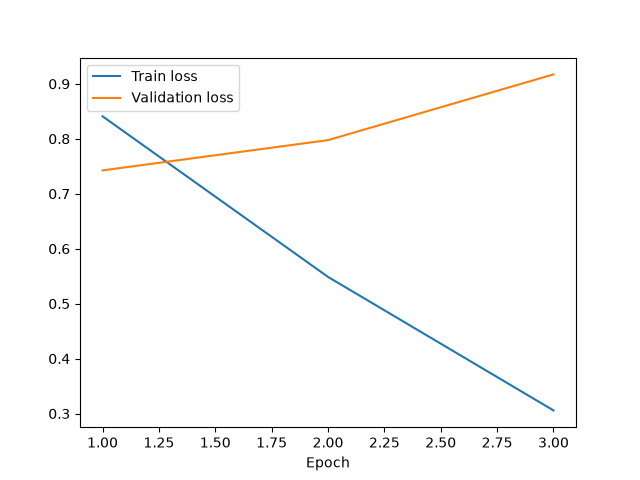

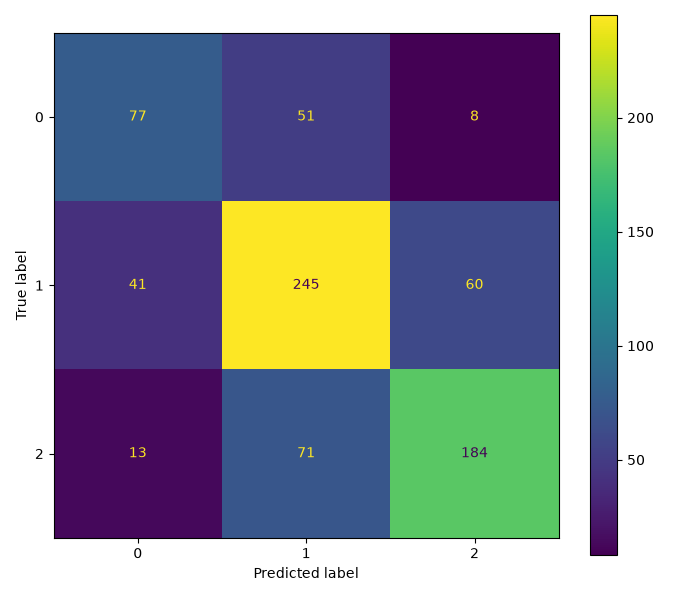

{
  "worst_class": "0",
  "examples": [
    {
      "text": "BREAKING NEWS: #Arrow will not be seen tonight in Illinois or Indiana due to the Chicago Bulls opening game. It will air on Saturday. :(",
      "actual": "0",
      "predicted": "1",
      "diagnosis": "REQUIRED: add a one-line human diagnosis"
    },
    {
      "text": "\"RT @user Final Destination 5? Pretty sure \\\"\"final\\\"\" means the last one...not the 5th one.\"",
      "actual": "0",
      "predicted": "1",
      "diagnosis": "REQUIRED: add a one-line human diagnosis"
    },
    {
      "text": "@user @user  said you made Keith Richards look baby faced.  *May not have actually said this.",
      "actual": "0",
      "predicted": "1",
      "diagnosis": "REQUIRED: add a one-line human diagnosis"
    },
    {
      "text": "Instead of being aghast at the spectacle of Trump's transition, liberals should try a more level-headed approach.\u2026",
      "actual": "0",
      "predicted": "1",
      "diagnosis": "REQUIRED

In [31]:
subprocess.run([sys.executable,'src/evaluate_bert.py'],check=True)
from IPython.display import display,Image
display(Image(filename='figures/training_curves.png'))
display(Image(filename='figures/confusion_matrix.png'))
print((ROOT/'results/worst_class_errors.json').read_text()[:5000])

## 4 — HW4.a serving baseline

The serving model is a separate causal LM (BERT classification cannot run in vLLM generation mode). Report **batch-completion p50/p95** as such; they are not true independent request latencies or TTFT. A concurrent client is required for true request-level latency. Increase repeats for stable percentiles.


In [40]:
%pip install -U vllm

  Using cached vllm-0.32.0-cp38-abi3-manylinux_2_28_x86_64.whl.metadata (11 kB)
  Using cached cachetools-7.2.6-py3-none-any.whl.metadata (5.5 kB)
  Using cached blake3-1.0.11-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (4.9 kB)
  Using cached transformers-5.19.0-py3-none-any.whl.metadata (32 kB)
  Using cached protobuf-7.36.2-cp310-abi3-manylinux2014_x86_64.whl.metadata (595 bytes)
  Using cached fastapi-0.136.3-py3-none-any.whl.metadata (27 kB)
  Using cached starlette-1.10.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached openai-3.40.0-py3-none-any.whl.metadata (44 kB)
  Using cached pydantic-2.14.1-py3-none-any.whl.metadata (133 kB)
  Using cached prometheus_fastapi_instrumentator-8.1.0-py3-none-any.whl.metadata (13 kB)
  Using cached tiktoken-0.14.0-cp312-cp312-manylinux_2_28_x86_64.whl.metadata (6.7 kB)
  Using cached lm_format_enforcer-0.11.3-py3-none-any.whl.metadata (17 kB)
  Using cached llguidance-1.7.6-cp39-abi3-manylinux_2_31_x86_64.whl.metadata (

In [73]:
import csv
import json
import shutil
import pandas as pd
from pathlib import Path

RESULTS = ROOT / "results"
path = RESULTS / "serving_metrics.csv"
backup = RESULTS / "serving_metrics_original_backup.csv"

# Preserve original CSV before changing anything
if path.exists() and not backup.exists():
    shutil.copy2(path, backup)

rows = []

# Recover CSV rows, including rows with additional columns
if backup.exists():
    with backup.open(newline="") as f:
        records = list(csv.reader(f))

    header = records[0]
    for record in records[1:]:
        if record and record[0] == "backend":
            header = record
        elif record and len(record) == len(header):
            rows.append(dict(zip(header, record)))
        elif record:
            print("Preserved unmatched CSV row in backup:", len(record), "columns")

# Recover exact vLLM metrics from saved logs
for batch in [1, 8, 32]:
    log = RESULTS / f"vllm_batch_{batch}.log"
    if not log.exists():
        continue

    for line in log.read_text(errors="replace").splitlines():
        try:
            data = json.loads(line.strip())
            if data.get("backend") == "vllm" and data.get("batch") == batch:
                rows = [
                    r for r in rows
                    if not (
                        r.get("backend") == "vllm"
                        and str(r.get("batch")) == str(batch)
                    )
                ]
                rows.append(data)
                break
        except json.JSONDecodeError:
            continue

# Write consistent CSV columns
if rows:
    df = pd.DataFrame(rows)
    df.to_csv(path, index=False)
    print("Repaired:", path)
    display(df[[
        c for c in [
            "backend", "batch", "tokens_per_second",
            "p50_batch_ms", "p95_batch_ms",
            "peak_allocated_gb", "gpu_used_gb_from_nvidia_smi",
            "status"
        ] if c in df.columns
    ]])
else:
    print("No records recovered. Original file preserved.")

Preserved unmatched CSV row in backup: 21 columns
Preserved unmatched CSV row in backup: 13 columns
Preserved unmatched CSV row in backup: 13 columns
Preserved unmatched CSV row in backup: 13 columns
Preserved unmatched CSV row in backup: 13 columns
Preserved unmatched CSV row in backup: 21 columns
Preserved unmatched CSV row in backup: 13 columns
Preserved unmatched CSV row in backup: 13 columns
Preserved unmatched CSV row in backup: 13 columns
Preserved unmatched CSV row in backup: 13 columns
Preserved unmatched CSV row in backup: 13 columns
Preserved unmatched CSV row in backup: 13 columns
Preserved unmatched CSV row in backup: 13 columns
Preserved unmatched CSV row in backup: 13 columns
Preserved unmatched CSV row in backup: 21 columns
Preserved unmatched CSV row in backup: 21 columns
Preserved unmatched CSV row in backup: 21 columns
Preserved unmatched CSV row in backup: 21 columns
Preserved unmatched CSV row in backup: 21 columns
Preserved unmatched CSV row in backup: 21 columns


,backend,batch,tokens_per_second,p50_batch_ms,p95_batch_ms,peak_allocated_gb,gpu_used_gb_from_nvidia_smi,status
0,hf,1,41.178,NaN,NaN,14.2405,14.814,NaN
1,vllm,1,62.023,771.253,781.968,NaN,18.484,ok
2,vllm,8,466.127,904.975,950.840,NaN,18.486,ok
3,vllm,32,1648.492,1005.931,1049.271,NaN,18.518,ok


In [ ]:
for backend,b in [('hf',1),('vllm',1),('vllm',8),('vllm',32)]:
    subprocess.run([sys.executable,'src/benchmark_vllm.py','--backend',backend,'--batch',str(b)],check=True)
import pandas as pd
display(pd.read_csv('results/serving_metrics.csv'))

## 5 — Part A: measured full-epoch batch scaling
Run successive batch sizes until OOM. Use measured samples/sec, peak allocated GPU memory and epoch seconds. Keep the same dataset, seed and training settings.


In [74]:
subprocess.run([sys.executable,'src/full_experiments.py','--mode','scaling','--max-batch','1024'],check=True)
display(pd.read_csv('results/full_batch_scaling.csv'))


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2663.41it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

{'technique': 'baseline_scaling', 'batch': 16, 'effective_batch': 16, 'amp': False, 'checkpoint': False, 'optimizer8': False, 'accum': 1, 'epochs_completed': 1, 'optimizer_steps': 219, 'train_samples': 3500, 'train_seconds': 11.63, 'wall_seconds_including_evaluation': 12.821, 'samples_per_second': 300.949, 'peak_gb': 2.4768, 'eval_accuracy': 0.6653333333333333, 'status': 'ok'}


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3742.13it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

{'technique': 'baseline_scaling', 'batch': 32, 'effective_batch': 32, 'amp': False, 'checkpoint': False, 'optimizer8': False, 'accum': 1, 'epochs_completed': 1, 'optimizer_steps': 110, 'train_samples': 3500, 'train_seconds': 7.833, 'wall_seconds_including_evaluation': 8.892, 'samples_per_second': 446.801, 'peak_gb': 3.7374, 'eval_accuracy': 0.636, 'status': 'ok'}


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4508.76it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

...

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3458.95it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

{'technique': 'baseline_scaling', 'batch': 256, 'effective_batch': 256, 'amp': False, 'checkpoint': False, 'optimizer8': False, 'accum': 1, 'epochs_completed': 1, 'optimizer_steps': 14, 'train_samples': 3500, 'train_seconds': 6.481, 'wall_seconds_including_evaluation': 7.484, 'samples_per_second': 540.018, 'peak_gb': 20.6844, 'eval_accuracy': 0.524, 'status': 'ok'}


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3636.24it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

{'technique': 'baseline_scaling', 'batch': 512, 'effective_batch': 512, 'status': 'OOM'}


,technique,batch,effective_batch,amp,checkpoint,optimizer8,accum,epochs_completed,optimizer_steps,train_samples,train_seconds,wall_seconds_including_evaluation,samples_per_second,peak_gb,eval_accuracy,status
0,baseline_scaling,16,16,False,False,False,1.0,1.0,219.0,3500.0,11.630,12.821,300.949,2.4768,0.665333,ok
1,baseline_scaling,32,32,False,False,False,1.0,1.0,110.0,3500.0,7.833,8.892,446.801,3.7374,0.636000,ok
2,baseline_scaling,64,64,False,False,False,1.0,1.0,55.0,3500.0,7.163,8.165,488.625,6.1355,0.566667,ok
3,baseline_scaling,128,128,False,False,False,1.0,1.0,28.0,3500.0,6.785,7.800,515.863,11.0256,0.545333,ok
4,baseline_scaling,256,256,False,False,False,1.0,1.0,14.0,3500.0,6.481,7.484,540.018,20.6844,0.524000,ok
5,baseline_scaling,512,512,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,OOM


## 6 — Part B: measured independent techniques and data-selected combination

Run baseline, AMP, checkpointing, gradient accumulation and 8-bit optimizer **first**. The script then selects eligible techniques based on observed memory, throughput and accuracy, writes `results/combination_selection.json`, and runs that combination. Compare accumulation separately because it changes effective batch. Selection thresholds are heuristics and must be justified in your report.


In [75]:
# Full-epoch, independently measured techniques. Scans max batch until OOM (can take time).
subprocess.run([sys.executable,'src/full_experiments.py','--mode','techniques','--scan-technique-max','--max-batch','1024'],check=True)
display(pd.read_csv('results/full_memory_comparison.csv'))


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4187.44it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

{'technique': 'baseline', 'batch': 16, 'effective_batch': 16, 'amp': False, 'checkpoint': False, 'optimizer8': False, 'accum': 1, 'epochs_completed': 3, 'optimizer_steps': 657, 'train_samples': 10500, 'train_seconds': 33.401, 'wall_seconds_including_evaluation': 35.811, 'samples_per_second': 314.357, 'peak_gb': 2.4768, 'eval_accuracy': 0.668, 'status': 'ok'}


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3588.17it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

{'technique': 'baseline', 'batch': 32, 'effective_batch': 32, 'amp': False, 'checkpoint': False, 'optimizer8': False, 'accum': 1, 'epochs_completed': 3, 'optimizer_steps': 330, 'train_samples': 10500, 'train_seconds': 23.685, 'wall_seconds_including_evaluation': 25.821, 'samples_per_second': 443.324, 'peak_gb': 3.7374, 'eval_accuracy': 0.6853333333333333, 'status': 'ok'}


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3563.68it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

...

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3329.62it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

{'technique': 'best_combination', 'batch': 256, 'effective_batch': 256, 'amp': False, 'checkpoint': False, 'optimizer8': False, 'accum': 1, 'epochs_completed': 3, 'optimizer_steps': 42, 'train_samples': 10500, 'train_seconds': 19.607, 'wall_seconds_including_evaluation': 21.638, 'samples_per_second': 535.53, 'peak_gb': 20.6844, 'eval_accuracy': 0.6293333333333333, 'status': 'ok'}


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4722.81it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

{'technique': 'best_combination', 'batch': 512, 'effective_batch': 512, 'status': 'OOM'}


,technique,batch,effective_batch,amp,checkpoint,optimizer8,accum,epochs_completed,optimizer_steps,train_samples,train_seconds,wall_seconds_including_evaluation,samples_per_second,peak_gb,eval_accuracy,status,details
0,baseline,16,16.0,False,False,False,1.0,3.0,657.0,10500.0,33.401,35.811,314.357,2.4768,0.668000,ok,NaN
1,baseline,32,32.0,False,False,False,1.0,3.0,330.0,10500.0,23.685,25.821,443.324,3.7374,0.685333,ok,NaN
2,baseline,64,64.0,False,False,False,1.0,3.0,165.0,10500.0,21.519,23.550,487.947,6.1355,0.656000,ok,NaN
3,baseline,128,128.0,False,False,False,1.0,3.0,84.0,10500.0,20.439,22.479,513.719,11.0256,0.664000,ok,NaN
4,baseline,256,256.0,False,False,False,1.0,3.0,42.0,10500.0,19.602,21.637,535.668,20.6844,0.629333,ok,NaN
5,baseline,512,512.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,OOM,NaN
6,mixed_precision,16,16.0,True,False,False,1.0,3.0,657.0,10500.0,37.326,38.945,281.304,2.2549,0.678667,ok,NaN
7,mixed_precision,32,32.0,True,False,False,1.0,3.0,330.0,10500.0,15.648,16.552,671.012,3.0408,0.673333,ok,NaN
8,mixed_precision,64,64.0,True,False,False,1.0,3.0,165.0,10500.0,10.314,11.076,1017.997,4.5663,0.673333,ok,NaN
9,mixed_precision,128,128.0,True,False,False,1.0,3.0,84.0,10500.0,9.497,10.284,1105.583,7.6724,0.653333,ok,NaN


## 7 — Plot measured single-card throughput and memory
Use only successful observed probes; do not treat estimated full-epoch seconds as measured.

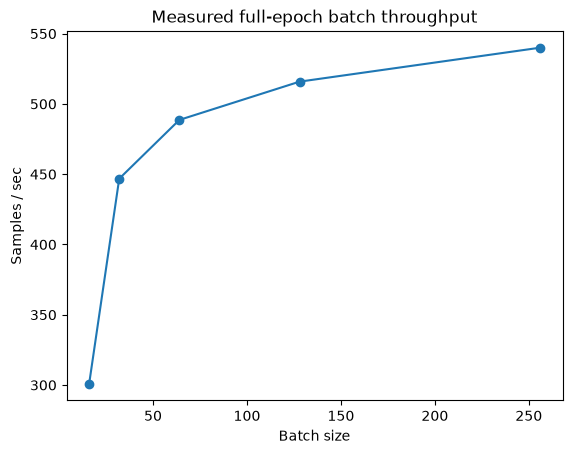

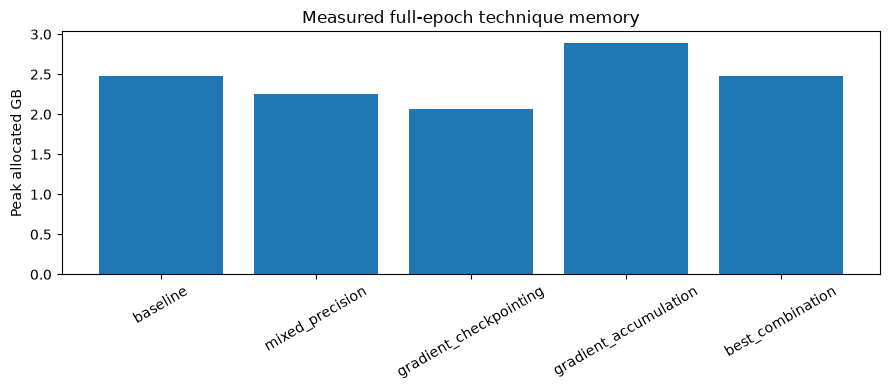

In [77]:
import matplotlib.pyplot as plt
from pathlib import Path
Path('figures').mkdir(exist_ok=True)
a=pd.read_csv('results/full_batch_scaling.csv');a=a[a.status=='ok']
fig,ax=plt.subplots();ax.plot(a.batch,a.samples_per_second,'o-');ax.set(xlabel='Batch size',ylabel='Samples / sec',title='Measured full-epoch batch throughput');fig.savefig('figures/throughput_vs_batch.png',bbox_inches='tight');plt.show()
b=pd.read_csv('results/full_memory_comparison.csv');b=b[(b.status=='ok') & (b.batch==int(c['batch_size']))].drop_duplicates('technique',keep='last')
fig,ax=plt.subplots(figsize=(9,4));ax.bar(b.technique,b.peak_gb);ax.tick_params(axis='x',rotation=30);ax.set(ylabel='Peak allocated GB',title='Measured full-epoch technique memory');fig.tight_layout();fig.savefig('figures/memory_comparison.png');plt.show()


## 9 — Part D: vLLM context/KV-cache sweep on one GPU

The script starts a **new vLLM engine** at increasing `max_model_len` values with batch 8, recording success/failure and full startup logs (including GPU-block messages when emitted by the installed vLLM version). It also records **analytical KV bytes/token**; `nvidia-smi` is vLLM's reserved process memory, **not** measured KV consumption. If the model's supported context limit is reached before an engine failure, say so; do not claim GPU exhaustion.


In [78]:
subprocess.run([sys.executable,'src/kv_context_sweep.py'],check=True)
display(pd.read_csv('results/kv_context_sweep.csv'))
print((ROOT/'results/kv_context_summary.json').read_text())


{'max_model_len': 512, 'batch': 8, 'requested_prefix_tokens': 416, 'status': 'FAILED', 'return_code': 1, 'gpu_blocks_reported': '', 'block_size_reported': '', 'log_file': 'results/kv_logs/context_512.log', 'elapsed_s': 9.78}


,max_model_len,batch,requested_prefix_tokens,status,return_code,gpu_blocks_reported,block_size_reported,log_file,elapsed_s
0,512,8,416,FAILED,1,NaN,NaN,results/kv_logs/context_512.log,9.78


{
  "longest_successful_max_model_len": null,
  "batch": 8,
  "tested_up_to_model_limit": 32768,
  "caveat": "If no failure before model limit, report model context limit, not GPU OOM; logs preserve startup cache-block messages. GPU reserved memory is not KV-cache usage."
}


## 10 — Part E: summary, RunPod evidence, and GPU-hours

Generate the measured GPU-hours log and preserve `nvidia-smi -L` output. Fill in qualitative written answers and record the instructor's optional-Part-C clarification. Use actual GPU identity, not a hard-coded RTX 4090 label.


In [79]:
subprocess.run([sys.executable,'src/finalize_evidence.py'],check=True)
subprocess.run([sys.executable,'src/summarize_results.py'],check=False)
print((ROOT/'gpu_hours.csv').read_text())
print((ROOT/'GPU_INFO.txt').read_text()[:1500])


Captured GPU identity and 32 timed rows. Note: sum may double-count overlapping experiment timings; do not use as total billed GPU-hours.
             technique  batch  samples_per_second  peak_gb  eval_accuracy
              baseline     16             314.357   2.4768       0.668000
              baseline     32             443.324   3.7374       0.685333
              baseline     64             487.947   6.1355       0.656000
              baseline    128             513.719  11.0256       0.664000
              baseline    256             535.668  20.6844       0.629333
       mixed_precision     16             281.304   2.2549       0.678667
       mixed_precision     32             671.012   3.0408       0.673333
       mixed_precision     64            1017.997   4.5663       0.673333
       mixed_precision    128            1105.583   7.6724       0.653333
       mixed_precision    256            1155.548  13.9061       0.618667
gradient_checkpointing     16             226.23

## 11 — Final checklist

- [ ] Original HW4.a Twitter CSV, unchanged SLICE and SEED, exact row range documented
- [ ] `GPU_INFO.txt` contains actual `nvidia-smi -L` output or screenshot saved
- [ ] HW4.a training/validation/testing, worst-class error diagnoses
- [ ] HF and vLLM throughput, p50/p95 latency, written analysis
- [ ] Part A measured full-epoch scaling, OOM boundary (one GPU)
- [ ] Part B independent techniques, maximum batch, full-run accuracy and throughput, ranked table
- [ ] Part C skipped (optional) written in METRICS.md
- [ ] Part D KV-cache memory and longest context at batch 8, one GPU
- [ ] Part E GPU-hours, best configuration, plots and complete measured results
- [ ] RUN_LOG.txt, AI_USE.md, applicable captures and records, Git tag hw4-5


## 12 — Submission audit and theory notes
Run the audit script after experiments. It reports missing outputs; it does not fabricate results. Read `SUBMISSION_AUDIT.md` and `THEORY_VIVA_GUIDE.md`.

In [80]:
subprocess.run([sys.executable,'src/submission_audit.py'],check=False)
print((ROOT/'results/audit_report.txt').read_text())


PASS | Exact dataset fingerprint | results/dataset_lock.json
PASS | Exact row range | results/row_range.json
PASS | HW4.a training baseline | results/hw4_baseline.json
PASS | Per-epoch curves | results/training_history.csv
PASS | Confusion matrix | figures/confusion_matrix.png
PASS | Full-epoch batch scaling | results/full_batch_scaling.csv
PASS | Full-epoch memory comparison | results/full_memory_comparison.csv
PASS | Serving benchmarks | results/serving_metrics.csv
PASS | GPU identification | GPU_INFO.txt
PASS | Metrics report | METRICS.md
PASS | Run log | RUN_LOG.txt
PASS | AI disclosure | AI_USE.md
PASS | GPU-hour record | gpu_hours.csv
PASS | results/full_batch_scaling.csv | []
PASS | results/full_memory_comparison.csv | []
PASS | results/serving_metrics.csv | []
PASS | Instructor-approved optional Part C statement
MANUAL REVIEW | Five worst-class misclassifications each need an original one-line diagnosis
MANUAL REVIEW | Training past best validation epoch: describe overfitting a